# 광고 A/B 테스트 분석

## 질문과 가설

광고 그룹(ad)과 공익광고 그룹(psa)의 사용자 전환율은 다른가?
그룹의 의미는 데이터 설명서의 정의를 따른다.

- 귀무가설 H₀: 두 그룹의 모집단 전환율은 같다.
- 대립가설 H₁: 두 그룹의 모집단 전환율은 다르다.
- 주요 지표: 전환 사용자 수 / 전체 사용자 수
- 분석 단위: 사용자
- 검정: 독립된 두 집단의 비율 차이에 대한 z검정
- 유의수준: 0.05
- 검정 방향: 양측

## 분석 원칙

p값과 함께 절대 차이(%p), 차이의 95% 신뢰구간,
상대 비율(배수)을 보고한다.

계획 배정 비율과 무작위 배정 과정을 확인하지 못했으므로,
SRM은 평가 불가로 기록하고 탐색적 비교를 진행한다.
관측된 약 96:4 비율을 계획 비율로 사용하지 않는다.

결과를 확인한 뒤 작성한 분석 계획은 사전 분석 계획으로 표현하지 않는다.
관측된 차이를 광고의 인과 효과로 단정하지 않는다.

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Markdown

CSV_PATH = Path("/Users/limsunghun/python/DI/AB_Test/marketing_AB.csv")
GROUPS = ["ad", "psa"]
ALPHA = 0.05

raw_df = pd.read_csv(
    CSV_PATH,
    dtype={"user id": "string"},
)

df = raw_df.copy()
rows_before = len(df)

print(f"데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}개 컬럼")
display(df.head())

데이터 크기: 588,101행 × 7개 컬럼


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## 데이터 점검

자료형, 결측치, 중복 사용자와 처치 라벨 충돌을 확인한다.
전환 여부는 True/False 또는 1/0이어야 한다.

중복이나 누락이 발견되면 임의로 삭제하지 않고 원인과 처리 기준을 확인한다.
사용자 단위 분석에 필요한 조건을 충족하지 못하면 실행을 중단한다.

Unnamed 컬럼은 저장 인덱스일 수 있으므로 완전 중복 비교에서만 제외한다.
이 파일에는 배정과 실제 노출을 독립적으로 대조할 정보가 없으므로,
처치 라벨에 문제가 없다는 사실이 실제 노출의 정확성을 보장하지 않는다.

In [14]:
required = {"user id", "test group", "converted"}

if not required.issubset(df.columns):
    raise ValueError(f"필수 컬럼 누락: {required - set(df.columns)}")

if df.empty:
    raise ValueError("데이터가 비어 있습니다.")

basic_summary = pd.DataFrame({
    "자료형": df.dtypes.astype(str),
    "결측치 수": df.isna().sum(),
    "결측률(%)": (df.isna().mean() * 100).round(3),
})
display(basic_summary)

ids = df["user id"]
missing_id = ids.isna() | ids.str.strip().eq("").fillna(False)
duplicate_id = ~missing_id & ids.duplicated(keep=False)

group_counts_per_user = (
    df.loc[~missing_id]
    .groupby("user id")["test group"]
    .nunique()
)
conflict_count = int((group_counts_per_user > 1).sum())

invalid_group = ~df["test group"].isin(GROUPS)
invalid_conversion = ~df["converted"].isin([True, False, 1, 0])

content_columns = [
    column for column in df.columns
    if not column.startswith("Unnamed:")
]
exact_duplicates = int(df.duplicated(subset=content_columns).sum())

quality_checks = pd.Series({
    "누락·공백 ID 행": int(missing_id.sum()),
    "중복 사용자 수": int(ids[duplicate_id].nunique()),
    "중복 사용자에 해당하는 전체 행": int(duplicate_id.sum()),
    "여러 처치 라벨에 등장한 사용자": conflict_count,
    "누락·잘못된 처치 라벨 행": int(invalid_group.sum()),
    "누락·잘못된 전환 값 행": int(invalid_conversion.sum()),
    "내용이 완전히 동일한 추가 행": exact_duplicates,
})

display(quality_checks.to_frame("건수"))

if duplicate_id.any():
    display(df.loc[duplicate_id].sort_values("user id").head(10))

if quality_checks.gt(0).any():
    raise ValueError("데이터 문제가 발견됐습니다. 처리 기준을 먼저 확인하세요.")

if set(df["test group"].unique()) != set(GROUPS):
    raise ValueError("ad와 psa 두 그룹이 모두 필요합니다.")

analysis_df = df.copy()
analysis_df["converted"] = analysis_df["converted"].astype(int)

rows_after = len(analysis_df)
processing_note = (
    "기본 점검을 통과하여 모든 행을 유지했다. "
    "converted만 계산용 0/1로 변환했다. "
    "저장 인덱스는 중복 비교에서만 제외했다."
)

print(f"처리 전 {rows_before:,}행 → 처리 후 {rows_after:,}행")
print(f"제거한 행: {rows_before - rows_after:,}행")
print("처리 이유:", processing_note)

,자료형,결측치 수,결측률(%)
Unnamed: 0,int64,0,0.0
user id,string,0,0.0
test group,str,0,0.0
converted,bool,0,0.0
total ads,int64,0,0.0
most ads day,str,0,0.0
most ads hour,int64,0,0.0


,건수
누락·공백 ID 행,0
중복 사용자 수,0
중복 사용자에 해당하는 전체 행,0
여러 처치 라벨에 등장한 사용자,0
누락·잘못된 처치 라벨 행,0
누락·잘못된 전환 값 행,0
내용이 완전히 동일한 추가 행,0


처리 전 588,101행 → 처리 후 588,101행
제거한 행: 0행
처리 이유: 기본 점검을 통과하여 모든 행을 유지했다. converted만 계산용 0/1로 변환했다. 저장 인덱스는 중복 비교에서만 제외했다.


## 배정 비율과 SRM

SRM은 관측된 그룹 크기를 사전에 계획한 배정 비율과 비교하는 검정이다.
계획 비율이 확인되지 않아 이번 분석에서는 SRM을 평가하지 않는다.

이는 SRM 통과나 실패를 뜻하지 않는다.
그룹 크기가 불균형하다는 이유만으로 오류라고 판단하지 않으며,
크기를 맞추기 위해 데이터를 임의로 제거하지 않는다.

In [15]:
allocation = (
    analysis_df["test group"]
    .value_counts()
    .reindex(GROUPS)
    .rename("사용자 수")
    .to_frame()
)
allocation["관측 비율(%)"] = (
    allocation["사용자 수"] / len(analysis_df) * 100
)

display(allocation.round(3))

srm_status = "평가 불가 — 사전 계획 배정 비율 미확인"
print("SRM:", srm_status)

,사용자 수,관측 비율(%)
test group,,
ad,564577,96.0
psa,23524,4.0


SRM: 평가 불가 — 사전 계획 배정 비율 미확인


## 노출 패턴 점검

요일·시간대는 그룹 내 비율로 비교하고 카이제곱 독립성 검정을 수행한다.
두 검정의 p값에는 Bonferroni 보정을 적용한다.
큰 표본에서 작은 차이도 유의할 수 있어 Cramér's V도 함께 확인한다.

Cramér’s V는 두 범주형 변수 사이의 연관성이 얼마나 강한지 나타내는 효과 크기이다.

total ads는 평균, 중앙값과 분위수로 분포를 비교한다.

이 변수들은 실험 중 노출 기록에서 만들어진 처치 후 변수일 수 있다.
따라서 분포 차이를 배정 오류로 단정하지 않으며,
분포가 비슷하다고 무작위 배정이 입증되는 것도 아니다.

이 점검은 SRM을 대체하지 않는다.
노출 관련 변수로 사용자를 제외하거나 전환율을 보정하지 않는다.

In [16]:
pattern_results = []

for column in ["most ads day", "most ads hour"]:
    if column not in analysis_df.columns:
        print(f"{column}: 컬럼이 없어 생략")
        continue

    values = (
        analysis_df[column]
        .astype("string")
        .fillna("(결측)")
        .replace(r"^\s*$", "(공백)", regex=True)
    )

    table = pd.crosstab(
        analysis_df["test group"], values
    ).reindex(GROUPS, fill_value=0)

    print(f"\n[{column}: 그룹 내 비율(%)]")
    display((table.div(table.sum(axis=1), axis=0) * 100).round(2))

    if table.shape[1] < 2:
        print("범주가 하나뿐이므로 검정 생략")
        continue

    chi2, p, _, expected = stats.chi2_contingency(
        table, correction=False
    )

    approximation_ok = bool((expected >= 5).all())
    dimension = min(table.shape[0] - 1, table.shape[1] - 1)
    cramers_v = np.sqrt(
        chi2 / (table.to_numpy().sum() * dimension)
    )

    pattern_results.append({
        "변수": column,
        "Cramér's V": cramers_v,
        "보정 p값": min(p * 2, 1) if approximation_ok else np.nan,
        "상태": (
            "근사 조건 충족"
            if approximation_ok
            else "기대 빈도 부족: p값 해석 보류"
        ),
    })

if pattern_results:
    display(pd.DataFrame(pattern_results))

if "total ads" in analysis_df.columns:
    ads = pd.to_numeric(analysis_df["total ads"], errors="coerce")
    invalid_ads = ads.isna() | ~np.isfinite(ads) | ads.lt(0)

    if invalid_ads.any():
        print(f"노출량 오류·누락 {invalid_ads.sum():,}행: 노출량 요약 보류")
    else:
        exposure_summary = (
            analysis_df[["test group"]]
            .assign(total_ads=ads)
            .groupby("test group")["total_ads"]
            .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
            .reindex(GROUPS)
        )
        print("\n[노출량 분포]")
        display(exposure_summary.round(2))


[most ads day: 그룹 내 비율(%)]


most ads day,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
test group,,,,,,,
ad,15.73,14.80,13.96,14.58,14.01,13.21,13.71
psa,16.17,14.89,12.15,13.00,16.60,12.36,14.84



[most ads hour: 그룹 내 비율(%)]


most ads hour,0,1,10,11,12,13,14,15,16,17,...,21,22,23,3,4,5,6,7,8,9
test group,,,,,,,,,,,,,,,,,,,,,
ad,0.94,0.82,6.63,7.82,8.01,8.06,7.75,7.59,6.37,5.95,...,5.12,4.52,3.46,0.46,0.12,0.13,0.35,1.09,3.01,5.28
psa,0.96,0.79,6.31,8.76,8.76,9.22,7.95,7.77,6.82,5.88,...,4.60,3.90,2.63,0.38,0.12,0.10,0.35,1.01,2.80,5.11


,변수,Cramér's V,보정 p값,상태
0,most ads day,0.020016,9.698135e-48,근사 조건 충족
1,most ads hour,0.018082,2.189148e-28,근사 조건 충족



[노출량 분포]


,count,mean,std,min,25%,50%,75%,90%,99%,max
test group,,,,,,,,,,
ad,564577.0,24.82,43.75,1.0,4.0,13.0,27.0,56.0,201.0,2065.0
psa,23524.0,24.76,42.86,1.0,4.0,12.0,26.0,59.0,206.0,907.0


## SRM 평가의 한계와 보조 점검

SRM(Sample Ratio Mismatch)은 관측된 그룹별 사용자 수가 사전에 계획한 배정 비율과 일치하는지 평가하는 검정이다. 이번 데이터에서는 계획 배정 비율을 확인할 수 없으므로 SRM을 평가하지 않는다. 관측된 약 96:4 비율을 계획 비율로 대신 사용하지 않으며, 현재 상태를 SRM 통과 또는 실패로 판단하지 않는다.

배정 비율 검정과 별개로 데이터의 중복 문제와 그룹별 노출 패턴을 확인하기 위해 다음 보조 점검을 수행한다.

### 1. 사용자 중복 및 그룹 간 중복 확인

분석 단위가 사용자이므로 `user id`가 고유한지, 동일 사용자가 `ad`와 `psa` 두 그룹에 모두 등장하는지 확인한다.

중복 사용자나 그룹 간 중복이 발견되면 임의로 삭제하지 않고 원인과 처리 기준을 먼저 확인한다. 중복이 없더라도 사용자 간 독립성이나 무작위 배정이 입증되는 것은 아니다.

### 2. 요일·시간대 분포 비교

`most ads day`와 `most ads hour`의 분포를 그룹별로 비교한다. 두 그룹의 크기가 다르므로 단순 사용자 수 대신 **각 그룹 내 비율**을 확인한다.

카이제곱 독립성 검정을 수행하고, 두 검정을 함께 수행하는 점을 고려하여 Bonferroni 보정을 적용한다. 기대 빈도가 부족하면 카이제곱 근사에 따른 p값의 해석을 보류한다.

큰 표본에서는 작은 차이도 통계적으로 유의할 수 있으므로, 분포 차이의 크기를 파악하기 위해 Cramér’s V를 함께 보고한다. 보정 p값이 유의수준 이상이더라도 두 분포가 동일하다고 결론 내리지 않는다.

요일과 시간대는 실험 중 노출 기록에서 만들어진 변수일 수 있으므로, 이 비교는 실험 전 공변량 균형 검증이 아닌 **노출 패턴의 탐색적 비교**로 해석한다.

### 3. 총 광고 노출량 분포 비교

`total ads`의 평균, 표준편차, 중앙값과 분위수를 비교하고, 상자그림과 누적분포 그래프로 분포의 차이를 확인한다.

`total ads`는 실험 중 측정된 처치 후 변수일 수 있다. 따라서 노출량 차이를 배정 오류의 증거로 단정하지 않으며, 이 변수를 기준으로 사용자를 제외하거나 전환율을 보정하지 않는다.

### 해석 범위

위 점검은 데이터의 중복 문제와 노출 패턴 차이를 살펴보기 위한 보조 분석이며, **SRM을 대체하거나 무작위 배정의 적절성을 증명하지 않는다.**

전환율 분석 결과는 사용자 간 독립성 등 통계적 전제를 가정한 탐색적 비교로 해석한다. 광고의 인과 효과로 해석하려면 무작위 배정 방식, 배정·노출 로그, 수집 누락, 사용자 포함·제외 기준과 전환 관찰 기간 등을 추가로 확인해야 한다.

이미 전환 결과를 확인한 뒤 이 계획을 작성했다면, 사전 등록된 분석 계획이 아니라 **결과 확인 후 작성한 분석 계획**임을 명시한다.


In [17]:
# 기존 점검 결과를 한곳에 요약합니다.
# SRM의 대체 검정이나 무작위 배정의 합격 판정이 아닙니다.

print("=== SRM 및 보조 점검 요약 ===")
print(f"\nSRM: {srm_status}")

print("\n[1. 사용자 중복·그룹 간 중복]")
display(
    quality_checks.loc[
        [
            "중복 사용자 수",
            "중복 사용자에 해당하는 전체 행",
            "여러 처치 라벨에 등장한 사용자",
        ]
    ].to_frame("건수")
)

print("\n[2. 요일·시간대 분포]")
if pattern_results:
    pattern_summary = pd.DataFrame(pattern_results).copy()

    def interpret_pattern(row):
        p = row["보정 p값"]

        if pd.isna(p):
            return "기대 빈도 부족으로 판단 보류"
        if p < ALPHA:
            return "그룹별 분포 차이의 통계적 증거가 있음"
        return "분포 차이의 증거가 부족함 — 동일함을 입증하지는 않음"

    pattern_summary["해석"] = pattern_summary.apply(
        interpret_pattern, axis=1
    )
    display(pattern_summary)
else:
    print("검정 가능한 요일·시간대 결과가 없습니다.")

print("\n[3. 총 노출량 분포]")
if "total ads" not in analysis_df.columns:
    print("컬럼이 없어 점검하지 못했습니다.")
else:
    ads_check = pd.to_numeric(
        analysis_df["total ads"], errors="coerce"
    )
    invalid = (
        ads_check.isna()
        | ~np.isfinite(ads_check)
        | ads_check.lt(0)
    )

    if invalid.any():
        print(
            f"누락·잘못된 값 {int(invalid.sum()):,}행: "
            "노출량 비교를 보류합니다."
        )
    else:
        display(
            analysis_df[["test group"]]
            .assign(total_ads=ads_check)
            .groupby("test group")["total_ads"]
            .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
            .reindex(GROUPS)
            .round(2)
        )

print(
    "\n해석 주의:\n"
    "- 위 점검은 SRM을 대체하거나 무작위 배정을 증명하지 않습니다.\n"
    "- 요일·시간대·노출량은 처치 후 변수일 수 있습니다.\n"
    "- 분포 차이를 배정 오류로 단정하거나, "
    "이 변수들로 사용자를 제외·전환율을 보정하지 않습니다.\n"
    "- 전환율 결과는 사용자 간 독립성 등을 가정한 "
    "탐색적 비교로 해석합니다."
)

=== SRM 및 보조 점검 요약 ===

SRM: 평가 불가 — 사전 계획 배정 비율 미확인

[1. 사용자 중복·그룹 간 중복]


,건수
중복 사용자 수,0
중복 사용자에 해당하는 전체 행,0
여러 처치 라벨에 등장한 사용자,0



[2. 요일·시간대 분포]


,변수,Cramér's V,보정 p값,상태,해석
0,most ads day,0.020016,9.698135e-48,근사 조건 충족,그룹별 분포 차이의 통계적 증거가 있음
1,most ads hour,0.018082,2.189148e-28,근사 조건 충족,그룹별 분포 차이의 통계적 증거가 있음



[3. 총 노출량 분포]


,count,mean,std,min,25%,50%,75%,90%,99%,max
test group,,,,,,,,,,
ad,564577.0,24.82,43.75,1.0,4.0,13.0,27.0,56.0,201.0,2065.0
psa,23524.0,24.76,42.86,1.0,4.0,12.0,26.0,59.0,206.0,907.0



해석 주의:
- 위 점검은 SRM을 대체하거나 무작위 배정을 증명하지 않습니다.
- 요일·시간대·노출량은 처치 후 변수일 수 있습니다.
- 분포 차이를 배정 오류로 단정하거나, 이 변수들로 사용자를 제외·전환율을 보정하지 않습니다.
- 전환율 결과는 사용자 간 독립성 등을 가정한 탐색적 비교로 해석합니다.


## 노출 패턴 시각화

요일과 시간대는 그룹별 전체 사용자를 기준으로 한 비율을 비교한다.
그룹 크기가 다르므로 단순 사용자 수로 비교하지 않는다.

총 광고 노출량은 상자그림과 누적분포 그래프로 확인한다.

- 상자그림: 중앙값, 가운데 50% 범위와 분포의 퍼짐을 비교
- 누적분포: 특정 노출량 이하인 사용자의 누적 비율을 비교

상자그림에서는 극단값 표시를 생략하지만 데이터는 삭제하지 않는다.
누적분포에는 모든 유효한 노출량을 포함하며,
큰 값까지 보기 위해 가로축에 로그 계열 눈금을 사용한다.

이 그래프는 노출 패턴을 설명하기 위한 탐색적 자료이다.
처치 후 변수일 수 있으므로 배정의 적절성이나 인과 효과를 입증하지 않는다.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

GROUPS = ["ad", "psa"]
COLORS = {"ad": "#2563EB", "psa": "#F97316"}

# 운영체제별 한글 폰트 문제를 피하도록 그래프 안은 영어로 표시합니다.
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

if not set(GROUPS).issubset(set(analysis_df["test group"].dropna())):
    raise ValueError("ad와 psa 그룹이 모두 필요합니다.")

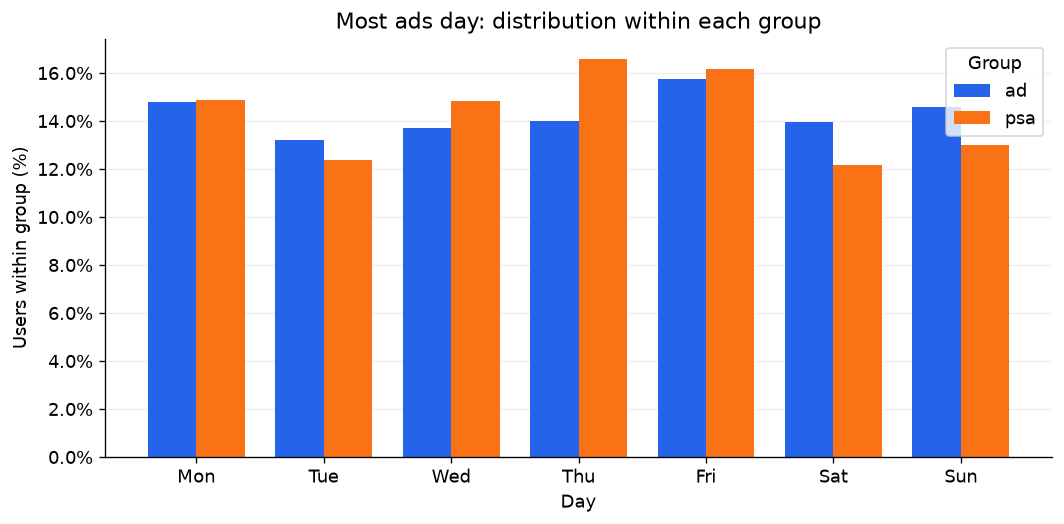

In [19]:
if "most ads day" not in analysis_df.columns:
    print("most ads day 컬럼이 없어 그래프를 생략합니다.")

else:
    day_order = [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ]

    day_values = (
        analysis_df["most ads day"]
        .astype("string")
        .fillna("Missing")
        .replace(r"^\s*$", "Blank", regex=True)
    )

    extra_categories = sorted(set(day_values) - set(day_order))
    categories = day_order + extra_categories

    day_counts = pd.crosstab(
        analysis_df["test group"], day_values
    ).reindex(index=GROUPS, columns=categories, fill_value=0)

    day_pct = day_counts.div(day_counts.sum(axis=1), axis=0) * 100

    x = np.arange(len(categories))
    width = 0.38

    fig, ax = plt.subplots(figsize=(max(9, len(categories)), 4.5))

    for group, offset in [("ad", -width / 2), ("psa", width / 2)]:
        ax.bar(
            x + offset,
            day_pct.loc[group],
            width=width,
            label=group,
            color=COLORS[group],
        )

    labels = [day[:3] for day in day_order] + extra_categories
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=25 if extra_categories else 0)
    ax.set_title("Most ads day: distribution within each group")
    ax.set_xlabel("Day")
    ax.set_ylabel("Users within group (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(title="Group")

    plt.tight_layout()
    plt.show()

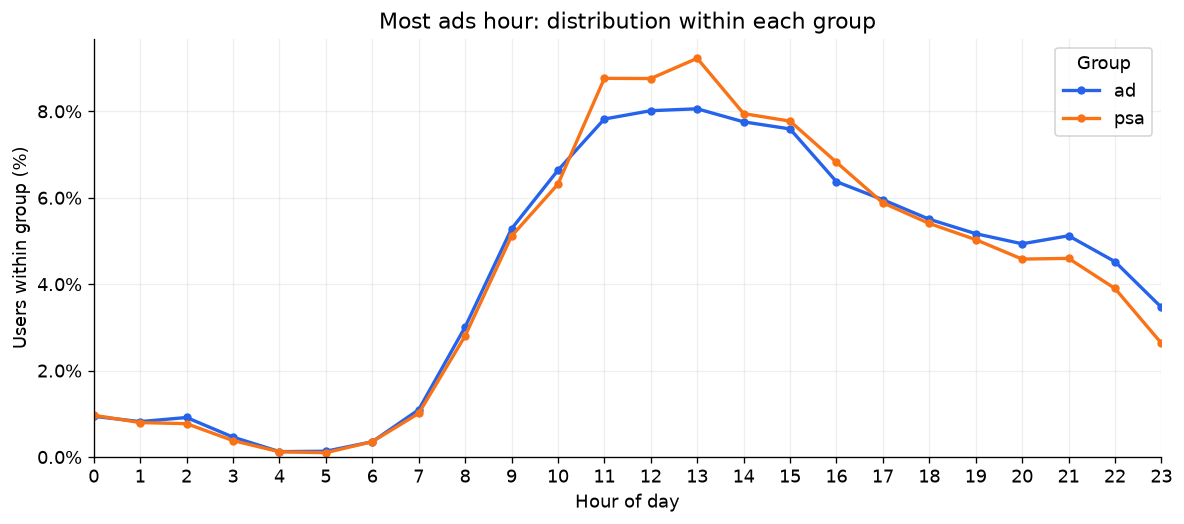

In [20]:
if "most ads hour" not in analysis_df.columns:
    print("most ads hour 컬럼이 없어 그래프를 생략합니다.")

else:
    hours = pd.to_numeric(
        analysis_df["most ads hour"], errors="coerce"
    )

    valid_hour = (
        hours.notna()
        & hours.between(0, 23)
        & hours.mod(1).eq(0)
    )

    if not valid_hour.all():
        print(
            f"누락·잘못된 시간 값 {int((~valid_hour).sum()):,}행이 있어 "
            "시간대 그래프를 보류합니다."
        )

    else:
        hour_counts = pd.crosstab(
            analysis_df["test group"],
            hours.astype(int),
        ).reindex(index=GROUPS, columns=range(24), fill_value=0)

        hour_pct = hour_counts.div(
            hour_counts.sum(axis=1), axis=0
        ) * 100

        fig, ax = plt.subplots(figsize=(10, 4.5))

        for group in GROUPS:
            ax.plot(
                range(24),
                hour_pct.loc[group],
                marker="o",
                markersize=4,
                linewidth=2,
                label=group,
                color=COLORS[group],
            )

        ax.set_title("Most ads hour: distribution within each group")
        ax.set_xlabel("Hour of day")
        ax.set_ylabel("Users within group (%)")
        ax.set_xticks(range(24))
        ax.set_xlim(0, 23)
        ax.set_ylim(bottom=0)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
        ax.grid(alpha=0.2)
        ax.legend(title="Group")

        plt.tight_layout()
        plt.show()

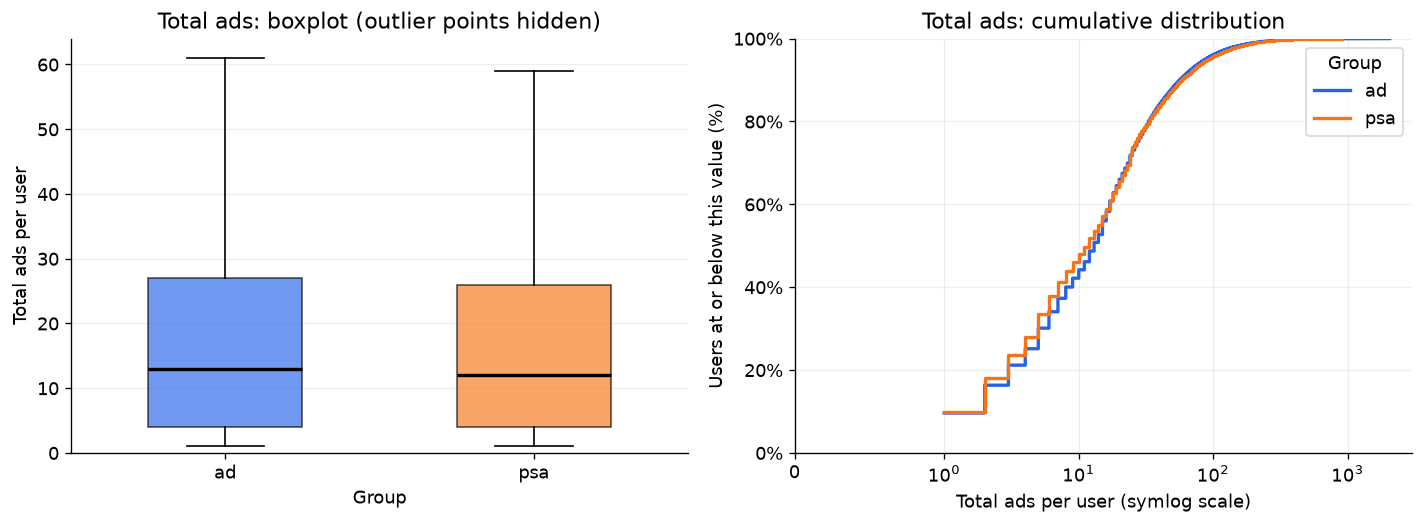

In [21]:
if "total ads" not in analysis_df.columns:
    print("total ads 컬럼이 없어 그래프를 생략합니다.")

else:
    ads = pd.to_numeric(analysis_df["total ads"], errors="coerce")

    invalid_ads = (
        ads.isna()
        | ~np.isfinite(ads)
        | ads.lt(0)
    )

    if invalid_ads.any():
        print(
            f"누락·잘못된 노출량 {int(invalid_ads.sum()):,}행이 있어 "
            "노출량 그래프를 보류합니다."
        )

    else:
        group_ads = {
            group: ads.loc[
                analysis_df["test group"].eq(group)
            ].to_numpy()
            for group in GROUPS
        }

        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

        # 왼쪽: 상자그림
        # showfliers=False는 극단값의 점 표시만 생략합니다.
        box = axes[0].boxplot(
            [group_ads[group] for group in GROUPS],
            patch_artist=True,
            showfliers=False,
            widths=0.5,
            medianprops={"color": "black", "linewidth": 2},
        )

        for patch, group in zip(box["boxes"], GROUPS):
            patch.set_facecolor(COLORS[group])
            patch.set_alpha(0.65)

        axes[0].set_xticks([1, 2])
        axes[0].set_xticklabels(GROUPS)
        axes[0].set_title("Total ads: boxplot (outlier points hidden)")
        axes[0].set_xlabel("Group")
        axes[0].set_ylabel("Total ads per user")
        axes[0].set_ylim(bottom=0)
        axes[0].grid(axis="y", alpha=0.2)

        # 오른쪽: 경험적 누적분포
        # 같은 노출량을 묶어 전체 데이터의 누적 비율을 계산합니다.
        for group in GROUPS:
            values, counts = np.unique(
                group_ads[group], return_counts=True
            )
            cumulative_pct = np.cumsum(counts) / counts.sum() * 100

            axes[1].step(
                values,
                cumulative_pct,
                where="post",
                label=group,
                color=COLORS[group],
                linewidth=2,
            )

        # 0도 표현할 수 있는 로그 계열 축
        axes[1].set_xscale("symlog", linthresh=1)
        axes[1].set_xlim(left=0)
        axes[1].set_ylim(0, 100)
        axes[1].set_title("Total ads: cumulative distribution")
        axes[1].set_xlabel("Total ads per user (symlog scale)")
        axes[1].set_ylabel("Users at or below this value (%)")
        axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
        axes[1].grid(alpha=0.2)
        axes[1].legend(title="Group")

        plt.tight_layout()
        plt.show()

## 전환율 차이 분석

전환 여부는 이진 변수이므로 두 비율 z검정을 사용한다.
사용자 간 독립성을 가정하며, 각 그룹의 전환·미전환 수가 충분한지 확인한다.

- 검정: 귀무가설 아래 합동 전환율로 표준오차 계산
- 차이의 신뢰구간: 각 그룹의 전환율을 사용한 비합동 표준오차
- 절대 차이: ad 전환율 − psa 전환율(%p)
- 상대 비율: ad 전환율 / psa 전환율(배수)
- 상대 변화율: (상대 비율 − 1) × 100%

비율 자료에서는 절대 차이 자체가 점추정이면서 효과 크기이다.
절대 차이와 상대 비율을 함께 보고하여 과장되거나 축소된 해석을 피한다.

p값이 0.05 이상이라고 두 전환율이 같다고 결론 내리지 않는다.
신뢰구간은 표본 오차를 표현하며 배정 오류나 선택 편향은 반영하지 않는다.

In [22]:
summary = (
    analysis_df.groupby("test group")["converted"]
    .agg(users="size", conversions="sum")
    .reindex(GROUPS)
)

summary["non_conversions"] = summary["users"] - summary["conversions"]
summary["conversion_rate"] = summary["conversions"] / summary["users"]

summary_display = summary.copy()
summary_display["conversion_rate"] = (
    summary_display["conversion_rate"].map(lambda x: f"{x:.3%}")
)
display(summary_display)

if (summary[["conversions", "non_conversions"]] < 10).any().any():
    raise ValueError(
        "전환·미전환 빈도가 작습니다. "
        "정규근사 대신 정확검정과 적절한 구간 추정을 검토하세요."
    )

n_ad, n_psa = summary["users"].astype(int)
x_ad, x_psa = summary["conversions"].astype(int)

p_ad = x_ad / n_ad
p_psa = x_psa / n_psa

# 점추정 및 절대 효과 크기
difference = p_ad - p_psa

# 합동 표준오차를 사용한 양측 z검정
pooled_rate = (x_ad + x_psa) / (n_ad + n_psa)
se_null = np.sqrt(
    pooled_rate * (1 - pooled_rate) * (1 / n_ad + 1 / n_psa)
)
z_stat = difference / se_null
p_value = 2 * stats.norm.sf(abs(z_stat))

# 절대 차이의 95% 신뢰구간
critical = stats.norm.ppf(1 - ALPHA / 2)
se_difference = np.sqrt(
    p_ad * (1 - p_ad) / n_ad
    + p_psa * (1 - p_psa) / n_psa
)
ci_low = difference - critical * se_difference
ci_high = difference + critical * se_difference

# 상대 효과 크기 및 로그 정규근사 신뢰구간
risk_ratio = p_ad / p_psa
relative_change = risk_ratio - 1

se_log_rr = np.sqrt(
    1 / x_ad - 1 / n_ad + 1 / x_psa - 1 / n_psa
)
rr_ci_low = np.exp(np.log(risk_ratio) - critical * se_log_rr)
rr_ci_high = np.exp(np.log(risk_ratio) + critical * se_log_rr)

p_text = f"{p_value:.3g}" if p_value > 0 else "수치 정밀도 한계로 0 표시"

results = pd.DataFrame({
    "항목": [
        "절대 차이(ad − psa)",
        "절대 차이의 95% 신뢰구간",
        "상대 비율(ad / psa)",
        "상대 비율의 95% 신뢰구간",
        "상대 변화율",
        "z통계량",
        "양측 p값",
    ],
    "결과": [
        f"{difference * 100:+.3f}%p",
        f"[{ci_low * 100:+.3f}, {ci_high * 100:+.3f}]%p",
        f"{risk_ratio:.3f}배",
        f"[{rr_ci_low:.3f}, {rr_ci_high:.3f}]배",
        f"{relative_change:+.2%}",
        f"{z_stat:.3f}",
        p_text,
    ],
})

display(results)

,users,conversions,non_conversions,conversion_rate
test group,,,,
ad,564577,14423,550154,2.555%
psa,23524,420,23104,1.785%


,항목,결과
0,절대 차이(ad − psa),+0.769%p
1,절대 차이의 95% 신뢰구간,"[+0.595, +0.943]%p"
2,상대 비율(ad / psa),1.431배
3,상대 비율의 95% 신뢰구간,"[1.300, 1.575]배"
4,상대 변화율,+43.09%
5,z통계량,7.370
6,양측 p값,1.71e-13


## 비용을 고려한 도입 기준

아래 금액은 실제 비용이 아닌 계산 예시이다.

- N: 도입 대상 사용자 수
- V: 추가 전환 1건의 기여이익
- C: psa 대비 사용자당 추가 비용
- F: 고정 도입 비용

손익분기 전환율 차이 = (N × C + F) / (N × V)

전환당 가치는 매출이 아니라 변동비를 차감한 기여이익으로 설정한다.
비용은 현재 비교 대상인 psa 대비 추가 비용으로 정의한다.

관측 차이가 인과 효과이고 도입 대상에도 유지된다는 조건에서만
예상 순이익 계산이 성립한다. 아래 결과는 가정에 따른 시나리오이며,
실제 수익 예측이나 출시 근거로 확정하지 않는다.

In [23]:
# 예시 가정값 — 실제 자료가 있으면 수정하세요.
TARGET_USERS = 100_000
VALUE_PER_CONVERSION = 20_000
EXTRA_COST_PER_USER = 100
FIXED_COST = 1_000_000

if TARGET_USERS <= 0 or VALUE_PER_CONVERSION <= 0:
    raise ValueError("사용자 수와 전환당 기여이익은 양수여야 합니다.")

total_cost = TARGET_USERS * EXTRA_COST_PER_USER + FIXED_COST

break_even_difference = (
    total_cost / (TARGET_USERS * VALUE_PER_CONVERSION)
)

def scenario_profit(rate_difference):
    return (
        TARGET_USERS * rate_difference * VALUE_PER_CONVERSION
        - total_cost
    )

profit_point = scenario_profit(difference)
profit_low = scenario_profit(ci_low)
profit_high = scenario_profit(ci_high)

if ci_low > break_even_difference:
    economic_assessment = (
        "차이의 신뢰구간 하한도 손익분기 기준을 넘는다. "
        "설계 타당성과 비용 가정이 확인된다면 경제적으로 유망하다."
    )
elif ci_high < break_even_difference:
    economic_assessment = (
        "차이의 신뢰구간 상한도 손익분기 기준에 못 미친다. "
        "현재 비용 가정에서는 도입을 지지하기 어렵다."
    )
else:
    economic_assessment = (
        "차이의 신뢰구간에 손익분기 기준이 포함되어 "
        "현재 추정만으로 경제성을 확정하기 어렵다."
    )

print(f"총 추가 비용: {total_cost:,.0f}원")
print(f"손익분기 전환율 차이: {break_even_difference * 100:.3f}%p")
print(f"관측 차이를 적용한 순이익: {profit_point:+,.0f}원")
print(
    "차이의 신뢰구간 양 끝을 적용한 순이익: "
    f"{profit_low:+,.0f}원 ~ {profit_high:+,.0f}원"
)
print(economic_assessment)

print(
    "\n※ 이 범위는 비용·기여이익을 고정한 상태에서 "
    "전환율 차이의 불확실성만 반영하며, 미래 이익의 예측구간은 아닙니다."
)

총 추가 비용: 11,000,000원
손익분기 전환율 차이: 0.550%p
관측 차이를 적용한 순이익: +4,384,906원
차이의 신뢰구간 양 끝을 적용한 순이익: +901,865원 ~ +7,867,948원
차이의 신뢰구간 하한도 손익분기 기준을 넘는다. 설계 타당성과 비용 가정이 확인된다면 경제적으로 유망하다.

※ 이 범위는 비용·기여이익을 고정한 상태에서 전환율 차이의 불확실성만 반영하며, 미래 이익의 예측구간은 아닙니다.


In [24]:
if p_value < ALPHA:
    statistical_conclusion = (
        "유의수준 0.05에서 귀무가설을 기각했다. "
        "독립성 등 통계적 전제가 성립한다면 "
        "두 그룹의 전환율이 다르다는 증거가 있다."
    )
else:
    statistical_conclusion = (
        "유의수준 0.05에서 귀무가설을 기각하지 못했다. "
        "두 전환율이 다르다는 증거가 부족하며, "
        "두 전환율이 같다는 의미는 아니다."
    )

final_report = f"""
# 광고 A/B 테스트 최종 보고서

## 1. 질문과 가설

광고 그룹(ad)과 공익광고 그룹(psa)의 사용자 전환율은 다른가?

- 귀무가설: 두 그룹의 모집단 전환율은 같다.
- 대립가설: 두 그룹의 모집단 전환율은 다르다.
- 유의수준 0.05의 양측검정을 사용했다.
- 결과 확인 후 작성한 계획은 사전 분석 계획으로 간주하지 않는다.

## 2. 데이터 위생 점검

자료형, 결측치, 사용자 ID 중복, 처치 라벨 충돌과 전환 값의 유효성을 확인했다.
현재 분석 데이터의 사용자 ID와 처치·전환 값에 분석을 막는 문제가 없었다.

- 처리 전: {rows_before:,}행
- 처리 후: {rows_after:,}행
- 제거: {rows_before - rows_after:,}행
- 처리 이유: {processing_note}

SRM은 계획 배정 비율 미확인으로 평가하지 못했다.
요일·시간대·노출량 점검은 탐색적 비교이며 SRM을 대체하지 않는다.

## 3. 검정 선택 근거

전환 여부가 이진 변수이고 두 그룹의 비율을 비교하므로
독립된 두 집단의 비율 차이에 대한 z검정을 사용했다.
각 그룹의 전환·미전환 수가 정규근사에 충분한지 확인했다.

검정에는 합동 표준오차를,
절대 차이의 신뢰구간에는 비합동 표준오차를 사용했다.

## 4. 결과

| 항목 | 결과 |
|---|---:|
| ad 사용자 수 | {n_ad:,} |
| psa 사용자 수 | {n_psa:,} |
| ad 전환율 | {p_ad:.3%} |
| psa 전환율 | {p_psa:.3%} |
| 점추정 및 절대 효과 크기 | {difference * 100:+.3f}%p |
| 절대 차이의 95% 신뢰구간 | [{ci_low * 100:+.3f}, {ci_high * 100:+.3f}]%p |
| 상대 비율 | {risk_ratio:.3f}배 |
| 상대 비율의 95% 신뢰구간 | [{rr_ci_low:.3f}, {rr_ci_high:.3f}]배 |
| 상대 변화율 | {relative_change:+.2%} |
| z통계량 | {z_stat:.3f} |
| 양측 p값 | {p_text} |

{statistical_conclusion}

### 비용을 고려한 시나리오

다음은 실제 확인된 비용이 아닌 예시 가정이다.

- 도입 대상: {TARGET_USERS:,}명
- 추가 전환당 기여이익: {VALUE_PER_CONVERSION:,.0f}원
- psa 대비 사용자당 추가 비용: {EXTRA_COST_PER_USER:,.0f}원
- 고정 도입 비용: {FIXED_COST:,.0f}원
- 손익분기 전환율 차이: {break_even_difference * 100:.3f}%p
- 관측 차이를 적용한 순이익: {profit_point:+,.0f}원

{economic_assessment}

이 계산은 관측 차이가 실제 인과 효과이고 도입 대상에서도 유지된다는
가정에 의존한다.

## 5. 의사결정

**선택: 데이터 추가 수집**

현재 결과만으로 출시를 확정하지 않는다.
우선 사용자 수를 늘리기보다 다음 정보를 확보한다.

1. 실험 당시 계획한 배정 비율과 무작위 배정 방식
2. 배정 로그와 실제 노출 로그
3. 수집 누락 및 사용자 포함·제외 기준
4. 그룹별 전환 관찰 기간과 측정 기준
5. 실제 추가 비용과 전환당 기여이익

설계 정보를 확보하면 SRM과 분석 타당성을 확인하고 경제성을 재평가한다.
기존 정보를 확보할 수 없다면 계획 배정 비율과 분석 기준을
사전에 명시한 새로운 실험을 고려한다.

## 6. 한계

- 무작위 배정 과정과 사용자 간 독립성이 확인되지 않았다.
- 계획 배정 비율을 몰라 SRM을 평가하지 못했다.
- 관측된 차이를 광고의 인과 효과로 단정할 수 없다.
- 신뢰구간은 선택 편향이나 수집 오류를 반영하지 않는다.
- 노출 관련 변수는 처치 후 변수일 수 있어 인과적 보정에 사용하지 않았다.
- 비용 계산은 예시 가정이며 실제 수익성을 입증하지 않는다.
- 결과가 다른 기간이나 대상에서도 유지되는지는 알 수 없다.
"""

display(Markdown(final_report))


# 광고 A/B 테스트 최종 보고서

## 1. 질문과 가설

광고 그룹(ad)과 공익광고 그룹(psa)의 사용자 전환율은 다른가?

- 귀무가설: 두 그룹의 모집단 전환율은 같다.
- 대립가설: 두 그룹의 모집단 전환율은 다르다.
- 유의수준 0.05의 양측검정을 사용했다.
- 결과 확인 후 작성한 계획은 사전 분석 계획으로 간주하지 않는다.

## 2. 데이터 위생 점검

자료형, 결측치, 사용자 ID 중복, 처치 라벨 충돌과 전환 값의 유효성을 확인했다.
현재 분석 데이터의 사용자 ID와 처치·전환 값에 분석을 막는 문제가 없었다.

- 처리 전: 588,101행
- 처리 후: 588,101행
- 제거: 0행
- 처리 이유: 기본 점검을 통과하여 모든 행을 유지했다. converted만 계산용 0/1로 변환했다. 저장 인덱스는 중복 비교에서만 제외했다.

SRM은 계획 배정 비율 미확인으로 평가하지 못했다.
요일·시간대·노출량 점검은 탐색적 비교이며 SRM을 대체하지 않는다.

## 3. 검정 선택 근거

전환 여부가 이진 변수이고 두 그룹의 비율을 비교하므로
독립된 두 집단의 비율 차이에 대한 z검정을 사용했다.
각 그룹의 전환·미전환 수가 정규근사에 충분한지 확인했다.

검정에는 합동 표준오차를,
절대 차이의 신뢰구간에는 비합동 표준오차를 사용했다.

## 4. 결과

| 항목 | 결과 |
|---|---:|
| ad 사용자 수 | 564,577 |
| psa 사용자 수 | 23,524 |
| ad 전환율 | 2.555% |
| psa 전환율 | 1.785% |
| 점추정 및 절대 효과 크기 | +0.769%p |
| 절대 차이의 95% 신뢰구간 | [+0.595, +0.943]%p |
| 상대 비율 | 1.431배 |
| 상대 비율의 95% 신뢰구간 | [1.300, 1.575]배 |
| 상대 변화율 | +43.09% |
| z통계량 | 7.370 |
| 양측 p값 | 1.71e-13 |

유의수준 0.05에서 귀무가설을 기각했다. 독립성 등 통계적 전제가 성립한다면 두 그룹의 전환율이 다르다는 증거가 있다.

### 비용을 고려한 시나리오

다음은 실제 확인된 비용이 아닌 예시 가정이다.

- 도입 대상: 100,000명
- 추가 전환당 기여이익: 20,000원
- psa 대비 사용자당 추가 비용: 100원
- 고정 도입 비용: 1,000,000원
- 손익분기 전환율 차이: 0.550%p
- 관측 차이를 적용한 순이익: +4,384,906원

차이의 신뢰구간 하한도 손익분기 기준을 넘는다. 설계 타당성과 비용 가정이 확인된다면 경제적으로 유망하다.

이 계산은 관측 차이가 실제 인과 효과이고 도입 대상에서도 유지된다는
가정에 의존한다.

## 5. 의사결정

**선택: 데이터 추가 수집**

현재 결과만으로 출시를 확정하지 않는다.
우선 사용자 수를 늘리기보다 다음 정보를 확보한다.

1. 실험 당시 계획한 배정 비율과 무작위 배정 방식
2. 배정 로그와 실제 노출 로그
3. 수집 누락 및 사용자 포함·제외 기준
4. 그룹별 전환 관찰 기간과 측정 기준
5. 실제 추가 비용과 전환당 기여이익

설계 정보를 확보하면 SRM과 분석 타당성을 확인하고 경제성을 재평가한다.
기존 정보를 확보할 수 없다면 계획 배정 비율과 분석 기준을
사전에 명시한 새로운 실험을 고려한다.

## 6. 한계

- 무작위 배정 과정과 사용자 간 독립성이 확인되지 않았다.
- 계획 배정 비율을 몰라 SRM을 평가하지 못했다.
- 관측된 차이를 광고의 인과 효과로 단정할 수 없다.
- 신뢰구간은 선택 편향이나 수집 오류를 반영하지 않는다.
- 노출 관련 변수는 처치 후 변수일 수 있어 인과적 보정에 사용하지 않았다.
- 비용 계산은 예시 가정이며 실제 수익성을 입증하지 않는다.
- 결과가 다른 기간이나 대상에서도 유지되는지는 알 수 없다.
